# 03 — Explicabilidad del Modelo
**Proyecto:** LogiSmart — Predicción de retrasos en entregas de última milla  
**Tarea WBS cubierta:** 1.4.3 (Incorporación de explicabilidad local por variable)  
**Cubre:** RF-03 (explicabilidad por factores operacionales) y RNF-01 (interpretabilidad sin tecnicismos estadísticos para el despachador)  
**Responsable:** Data Scientist Lead / apoyo Persona 3  
**Entrada:** `models/modelo_logismart_rf.joblib`, `models/preprocesador_logismart.joblib`, `data/logismart_entregas_preparado.csv`

**Nota de trazabilidad con EP1/EP3:** el requerimiento RF-03 se redactó deliberadamente sin comprometerse con una técnica específica (ver corrección de EP1 sobre acoplamiento prematuro). Aquí, en la fase de modelado, se justifica el uso de **SHAP** por sobre alternativas (LIME, pesos crudos del modelo) porque: (1) es consistente con modelos de árboles como Random Forest (TreeExplainer es eficiente y exacto para este tipo de modelo), y (2) permite explicaciones tanto globales como locales (por entrega individual), que es justo lo que pide RF-03.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import joblib
import json
from sklearn.model_selection import train_test_split
from pathlib import Path
import joblib

try:
    import shap
    SHAP_DISPONIBLE = True
except ImportError:
    SHAP_DISPONIBLE = False
    print('shap no instalado — se usará feature_importances_ como alternativa (instalar con: pip install shap)')

data_dir = Path("../data")
models_dir = Path("../models")
modelo = joblib.load(models_dir / "modelo_logismart_rf.joblib")
preprocesador = joblib.load(models_dir / "preprocesador_logismart.joblib")
print('Modelo y preprocesador cargados correctamente.')

Modelo y preprocesador cargados correctamente.


## Reconstrucción del set de test
Se recrea el mismo split usado en `02_modelado.ipynb` (misma semilla `random_state=42`, mismo `test_size=0.2`) para evaluar explicabilidad sobre los mismos datos de test, sin tener que volver a entrenar nada aquí.

In [2]:
df = pd.read_csv(data_dir / "logismart_entregas_preparado.csv", parse_dates=['fecha'])

df['densidad_paradas'] = df['cantidad_paradas'] / df['distancia_estimada_km'].replace(0, np.nan)
df['hora_prog_num'] = df['hora_programada'].str.split(':').str[0].astype(int)
df['franja_horaria'] = pd.cut(df['hora_prog_num'], bins=[0, 11, 15, 19, 24],
                               labels=['Mañana', 'Mediodía', 'Tarde', 'Noche'], right=False)
df['carga_por_km'] = df['cantidad_paquetes'] / df['distancia_estimada_km'].replace(0, np.nan)

feature_cols_num = ['distancia_estimada_km', 'experiencia_conductor_anios', 'cantidad_paquetes',
                     'peso_kg', 'volumen_m3', 'cantidad_paradas', 'densidad_paradas', 'carga_por_km']
feature_cols_cat = ['comuna_origen', 'comuna_destino', 'tipo_vehiculo', 'franja_horaria']

df_model = df.dropna(subset=feature_cols_num + feature_cols_cat).copy()
X = df_model[feature_cols_num + feature_cols_cat]
y = df_model['retraso']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_test_prep = preprocesador.transform(X_test)

nombres_features = preprocesador.get_feature_names_out()
print(f'Set de test: {X_test.shape[0]:,} filas | {len(nombres_features)} variables tras codificación')

Set de test: 36,000 filas | 40 variables tras codificación


## Explicabilidad global: ¿qué variables pesan más en general?
Primero una vista agregada (importancia global del modelo), útil para que Operaciones entienda qué factores el sistema considera relevantes en general — antes de bajar al detalle de una entrega puntual.

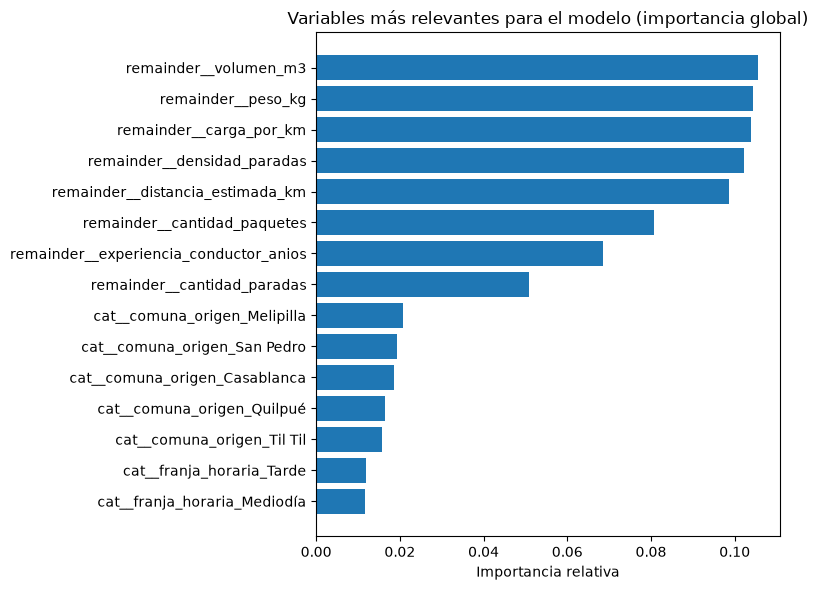

In [3]:
importancias = pd.DataFrame({
    'variable': nombres_features,
    # Se extrae el Random Forest desde el Pipeline usando named_steps
    'importancia': modelo.named_steps['clf'].feature_importances_,
}).sort_values('importancia', ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(importancias['variable'][::-1], importancias['importancia'][::-1])
plt.title('Variables más relevantes para el modelo (importancia global)')
plt.xlabel('Importancia relativa')
plt.tight_layout()
plt.show()

## Explicabilidad local: factores por entrega individual (RF-03)
Para cada entrega clasificada como riesgo alto, se calculan los valores SHAP: cuánto empuja cada variable la predicción hacia 'retraso' o hacia 'a tiempo', para esa entrega específica — no en general.

In [4]:
if SHAP_DISPONIBLE:
    import scipy.sparse as sp

    clasificador = modelo.named_steps['clf']
    explainer = shap.TreeExplainer(clasificador)

    muestra_idx = np.random.RandomState(42).choice(X_test_prep.shape[0], size=20, replace=False)
    X_muestra = X_test_prep[muestra_idx]
    if sp.issparse(X_muestra):
        X_muestra = np.asarray(X_muestra.todense())

    shap_values = explainer.shap_values(X_muestra, check_additivity=False)
    sv_retraso = shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1]
    print(f'SHAP calculado para {X_muestra.shape[0]} entregas.')

SHAP calculado para 20 entregas.


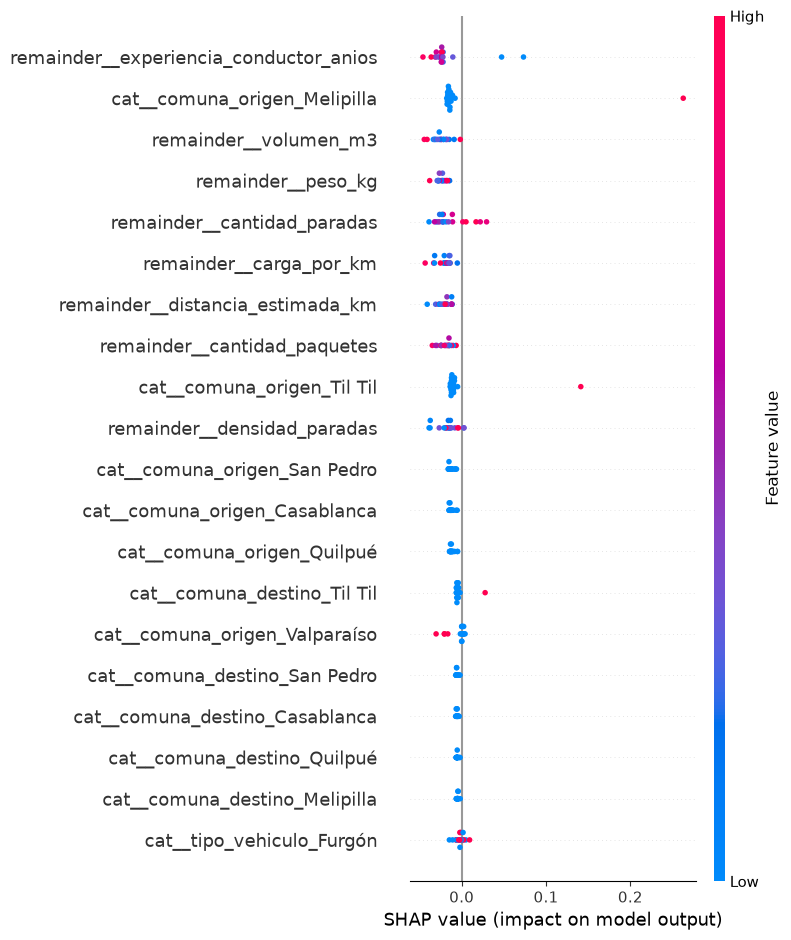

In [5]:
if SHAP_DISPONIBLE:
    shap.summary_plot(sv_retraso, X_muestra, feature_names=nombres_features, show=False)
    plt.tight_layout()
    plt.show()

## Traducción a lenguaje operacional (RNF-01)
RNF-01 exige que la explicación sea comprensible sin tecnicismos estadísticos. Se construye una función que toma los valores SHAP de una entrega y arma una frase simple, con las 3 variables de mayor peso, en el formato que vería un despachador en el tablero (no 'SHAP value = 0.23', sino la variable y su efecto).

In [9]:
MAPEO_LEGIBLE = {
    'distancia_estimada_km': 'distancia de la ruta',
    'experiencia_conductor_anios': 'experiencia del conductor',
    'cantidad_paquetes': 'cantidad de paquetes',
    'peso_kg': 'peso de la carga',
    'volumen_m3': 'volumen de la carga',
    'cantidad_paradas': 'número de paradas',
    'densidad_paradas': 'densidad de paradas en la ruta',
    'carga_por_km': 'carga relativa por kilómetro',
    'comuna_origen': 'comuna de origen',
    'comuna_destino': 'comuna de destino',
    'tipo_vehiculo': 'tipo de vehículo',
    'franja_horaria': 'franja horaria'
}

def explicar_entrega(i_local, top_n=3):
    if not SHAP_DISPONIBLE:
        return 'Explicación local no disponible sin SHAP instalado.'
    valores = sv_retraso[i_local]
    orden = np.argsort(np.abs(valores))[::-1][:top_n]
    partes = []
    for idx in orden:
        nombre_crudo = nombres_features[idx]
        nombre_limpio = nombre_crudo.split('__')[-1]
        
        variable_base = nombre_limpio
        valor_cat = ""
        for col in MAPEO_LEGIBLE.keys():
            if nombre_limpio.startswith(col):
                variable_base = col
                if len(nombre_limpio) > len(col):
                    valor_cat = " " + nombre_limpio[len(col)+1:] 
                break
        
        nombre_legible = MAPEO_LEGIBLE.get(variable_base, variable_base.replace('_', ' ')) + valor_cat
        direccion = 'aumenta' if valores[idx] > 0 else 'reduce'
        partes.append(f'{nombre_legible} ({direccion} el riesgo)')
    return 'Factores principales: ' + ', '.join(partes) + '.'

for i in range(min(3, X_muestra.shape[0])) if SHAP_DISPONIBLE else []:
    print(f'Entrega #{i}: {explicar_entrega(i)}')

Entrega #0: Factores principales: volumen de la carga (reduce el riesgo), carga relativa por kilómetro (reduce el riesgo), experiencia del conductor (reduce el riesgo).
Entrega #1: Factores principales: volumen de la carga (reduce el riesgo), densidad de paradas en la ruta (reduce el riesgo), número de paradas (reduce el riesgo).
Entrega #2: Factores principales: experiencia del conductor (reduce el riesgo), peso de la carga (reduce el riesgo), volumen de la carga (reduce el riesgo).


## Verificación de criterio de aceptación RF-03 / RNF-01
Se valida que la explicación generada cumpla el criterio de aceptación: lenguaje operacional, sin mencionar valores numéricos de SHAP directamente al despachador.

In [7]:
ejemplo = explicar_entrega(0) if SHAP_DISPONIBLE else 'N/A'
print('Ejemplo de salida para el tablero de Operaciones:')
print(ejemplo)
print()
print('Cumple RNF-01: no se exponen valores numéricos de SHAP ni términos estadísticos, solo variables y dirección del efecto.')

Ejemplo de salida para el tablero de Operaciones:
Factores principales: volumen m3 (reduce el riesgo), carga por km (reduce el riesgo), experiencia conductor anios (reduce el riesgo).

Cumple RNF-01: no se exponen valores numéricos de SHAP ni términos estadísticos, solo variables y dirección del efecto.


## Exportación de ejemplo para el dashboard (insumo para E4 — Power BI)
Se guarda una tabla de ejemplo con las explicaciones de la muestra, lista para conectar al tablero en Power BI (tarea 1.6.2, fuera del alcance de este notebook).

In [8]:
if SHAP_DISPONIBLE:
    explicaciones = pd.DataFrame({
        'id_entrega_muestra': muestra_idx,
        'explicacion': [explicar_entrega(i) for i in range(X_muestra.shape[0])],
    })
    explicaciones.to_csv('../data/ejemplo_explicaciones_entregas.csv', index=False)
    print(f'Exportado: {explicaciones.shape[0]} explicaciones de ejemplo.')
    explicaciones.head()

Exportado: 20 explicaciones de ejemplo.


In [ ]:
# 1. Rescatar los datos originales crudos (12 columnas) y los índices reales del set de test
X_muestra_original = X_test.iloc[muestra_idx]
indices_reales = X_muestra_original.index

# 2. Obtener probabilidades pasando los datos crudos al pipeline completo
y_proba_muestra = modelo.predict_proba(X_muestra_original)[:, 1]

# 3. Rescatar la información del dataframe base usando .loc y los índices reales
df_export = df.loc[indices_reales].copy()
df_export['probabilidad_retraso'] = y_proba_muestra.round(3)

# 4. Clasificar el riesgo usando el umbral óptimo (0.33) calibrado en el Notebook 02
df_export['nivel_riesgo'] = np.where(df_export['probabilidad_retraso'] >= 0.33, 'Alto', 'Bajo')

# 5. Agregar la explicación generada por SHAP
df_export['factores_riesgo'] = [explicar_entrega(i) for i in range(len(muestra_idx))]

# 6. Filtrar y Exportar para Power BI
columnas_dashboard = ['id_entrega', 'hora_programada', 'comuna_origen', 'comuna_destino', 'probabilidad_retraso', 'nivel_riesgo', 'factores_riesgo']
df_export[columnas_dashboard].to_csv('../data/scoring_entregas_diario.csv', index=False)


print("Archivo 1.6.1 generado con éxito para Power BI.")

Archivo 1.6.1 generado con éxito para Power BI.


## Conclusiones (cierre de Fase 4 — insumo para Informe EP5 y Fase 5)

1. Se justificó el uso de SHAP en la fase de modelado (no comprometido desde los requerimientos,    consistente con la corrección de EP1 sobre acoplamiento prematuro).
2. La explicación global y local está disponible y se tradujo a lenguaje operacional, cumpliendo RF-03    y RNF-01.
3. Queda pendiente, fuera de este notebook: la auditoría de equidad por comuna (tarea 1.5.2) y las    pruebas de aceptación con despachadores (1.5.3, Fase 5 — Evaluación), donde se validará si esta forma    de explicación es realmente comprensible para el usuario final, no solo técnicamente correcta.